# Multi-model UNSEEN hottest day of the year (TXx) in Australia (additive bias-corrected)

This notebook was generated using papermill:
```bash
papermill -p metric txx -p obs_config_file AGCD-CSIRO_r05_tasmax_config.mk -p obs AGCD -p bc additive spatial_analysis_multimodel.ipynb project-txx/spatial_analysis_multimodel_txx_AGCD-CSIRO_r05_bias-corrected-additive.ipynb
```

In [16]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
import xarray as xr

from spatial_plots_multimodel import *

plt.rcParams["figure.dpi"] = 300

In [2]:
# Default parameters
bc = None

In [3]:
# Parameters
metric = "txx"
obs_config_file = "AGCD-CSIRO_r05_tasmax_config.mk"
obs = "AGCD"
bc = "additive"

In [4]:
# Required parameters
kwargs = locals()
assert "metric" in kwargs, "Must provide a metric name (e.g., txx)"
assert (
    "obs_config_file" in kwargs
), "Must provide a obs_config_file name (e.g., AGCD-tasmax_config.mk)"
assert "obs" in kwargs, "Must provide a observation data set name (e.g., AGCD)"

In [5]:
if metric == "txx":
    models = np.array(
        [
            "CAFE",
            "BCC-CSM2-MR",
            "CanESM5",
            "CMCC-CM2-SR5",
            "EC-Earth3",
            "IPSL-CM6A-LR",
            "MIROC6",
            "MPI-ESM1-2-HR",
            "MRI-ESM2-0",
            "NorCPM1",
        ]
    )
elif metric == "rx1day":
    models = np.array(
        [
            "BCC-CSM2-MR",
            "CanESM5",
            "CMCC-CM2-SR5",
            "EC-Earth3",
            "HadGEM3-GC31-MM",
            "IPSL-CM6A-LR",
            "MIROC6",
            "MPI-ESM1-2-HR",
            "MRI-ESM2-0",
            "NorCPM1",
        ]
    )

In [6]:
# Get variables from makefile (nested dictionary)
var_dict = get_makefile_vars(models, metric, obs, obs_config_file=obs_config_file)

In [7]:
# Filestem for figures and datatree
filestem = f"{metric}_{var_dict[obs]['timescale']}_{var_dict[obs]['region']}"
if bc is not None:
    filestem += f"_bias-corrected-{var_dict[obs]['obs_dataset']}-{bc}"
dt_file = f"{var_dict[obs]['project_dir']}/data/datatree_{filestem}.nc"

In [8]:
# Extract some variables from the dictionaries
plot_dict = eval(var_dict[obs]["plot_dict"])
var = var_dict[obs]["var"]
time_agg = var_dict[obs]["time_agg"]
covariate_base = int(var_dict[obs]["covariate_base"])
covariates = eval(var_dict[obs]["gev_trend_period"])
plot_dict["fig_dir"] = Path(var_dict[obs]["fig_dir"]) / "multimodel"
plot_dict["filestem"] = filestem
plot_dict["filestem_no_bc"] = filestem.split("_bias")[0]
plot_dict["models"] = models

plot_dict_avg = plot_dict.copy()
stability_kwargs = {}
stability_anom_kwargs = {}

if metric == "txx":
    std_dev_ticks = np.arange(0, 4.5, 0.5)  # Median absolute deviation
    if bc is None:
        plot_dict_avg["ticks"] = np.arange(22, 52 + 4, 4)
        plot_dict["ticks"] = np.arange(24, 66 + 4, 4)
    else:
        plot_dict_avg["ticks"] = np.arange(22, 52 + 4, 4)
        plot_dict["ticks"] = np.arange(32, 56 + 2, 2)

    stability_anom_kwargs = dict(
        ticks=np.arange(-3.3, 3.5, 0.2),
        ticklabels=np.around(np.arange(-3.2, 3.4, 0.2), 1),
    )

elif metric == "rx1day":
    std_dev_ticks = np.arange(0, 50 + 10, 10)  # Median absolute deviation
    if bc is None:
        plot_dict_avg["ticks"] = np.arange(0, 200 + 20, 20)
        plot_dict["ticks"] = np.arange(0, 400 + 50, 50)
    else:
        plot_dict_avg["ticks"] = np.arange(0, 120 + 20, 20)
        plot_dict_avg["ticks_anom"] = np.arange(-11, 11 + 2, 2)
        plot_dict["ticks"] = np.arange(0, 450 + 50, 50)
        plot_dict["ticks_anom"] = np.arange(-170, 170 + 40, 40)

In [9]:
# Create/open datatree of all model and observation datasets
if Path(dt_file).exists():
    dt = xr.open_datatree(dt_file)
else:
    # Create a data tree using dict of {model: filenames["metric_fcst"]}
    data_dict = {}
    data_dict[f"obs/{obs}"] = open_obs_dataset(var_dict, obs)
    for i, model in enumerate(models):
        print(f"{i}. {model}")
        data_dict[f"model/{model}"] = open_model_dataset(var_dict[model], bc)
    dt = xr.DataTree.from_dict(data_dict)
    dt.to_netcdf(dt_file, compute=True)

dt

<xarray.DataTree>
Group: /
├── Group: /obs
│   └── Group: /obs/AGCD
│           Dimensions:     (time: 63, lat: 70, lon: 89, dparams: 5)
│           Coordinates:
│             * lat         (lat) float64 560B -44.5 -44.0 -43.5 -43.0 ... -11.0 -10.5 -10.0
│             * lon         (lon) float64 712B 112.0 112.5 113.0 113.5 ... 155.0 155.5 156.0
│             * time        (time) datetime64[ns] 504B 1961-06-30 1962-06-30 ... 2023-06-30
│               event_time  (time, lat, lon) datetime64[ns] 3MB ...
│             * dparams     (dparams) <U10 200B 'c' 'location_0' ... 'scale_0' 'scale_1'
│           Data variables:
│               tasmax      (time, lat, lon) float32 2MB ...
│               dparams_ns  (lat, lon, dparams) float64 249kB ...
│           Attributes: (12/34)
│               url:                           http://www.bom.gov.au/climate/
│               geospatial_lon_min:            111.975
│               bom-cmp-awap_version:          bom-cmp-awap-1.00-100.1.x86_64
│               id:                            Australian Gridded Climate Data (AGCD)
│               keywords:                      Earth Science, Atmosphere, Atmospheric Tem...
│               time_coverage_start:           1910-01-01T09:00:00
│               ...                            ...
│               geospatial_lat_min:            -44.525
│               analysis_components:           mean: the gridded temperature value
│               netcdf_version:                4.3.0 of Jul 16 2013 05:46:56 $
│               date_created:                  2018-08-16T23:46:11.477864
│               licence:                       Copyright for any data supplied by the Bur...
│               cdm_data_type:                 Grid
└── Group: /model
    ├── Group: /model/CAFE
    │       Dimensions:          (sample: 34944, lat: 19, lon: 19, dparams: 5, month: 2,
    │                             lead_time: 9, quantile: 2, bounds: 2)
    │       Coordinates:
    │         * lon              (lon) float64 152B 111.2 113.8 116.2 ... 151.2 153.8 156.2
    │         * lat              (lat) float64 152B -45.51 -43.48 -41.46 ... -11.12 -9.101
    │         * dparams          (dparams) <U10 200B 'c' 'location_0' ... 'scale_1'
    │         * lead_time        (lead_time) int64 72B 0 1 2 3 4 5 6 7 8
    │         * month            (month) int64 16B 5 11
    │         * quantile         (quantile) float64 16B 0.005 0.995
    │         * bounds           (bounds) <U5 40B 'lower' 'upper'
    │           event_time       (sample, lat, lon) object 101MB ...
    │           ensemble         (sample) int64 280kB ...
    │           init_date        (sample) object 280kB ...
    │           time             (sample) object 280kB ...
    │       Dimensions without coordinates: sample
    │       Data variables:
    │           tasmax           (sample, lat, lon) float32 50MB ...
    │           ks_pval          (lat, lon) float32 1kB ...
    │           pval_mask        (lat, lon) bool 361B ...
    │           dparams_ns       (lat, lon, dparams) float64 14kB ...
    │           covariate        (sample) int64 280kB ...
    │           r                (month, lead_time, lat, lon) float64 52kB ...
    │           ci               (month, quantile, lat, lon) float64 12kB ...
    │           min_lead         (month, lat, lon) int64 6kB ...
    │           min_lead_median  (month) float64 16B ...
    │           ci_median        (lat, lon, bounds) float64 6kB ...
    │           ci_aep           (lat, lon, bounds) float64 6kB ...
    │       Attributes:
    │           filename:   atmos_hybrid_daily.zarr
    │           grid_tile:  N/A
    │           grid_type:  regular
    │           title:      AccessOcean-AM2
    │           history:    Thu May 15 04:26:31 2025: /g/data/xv83/as3189/conda/envs/unse...
    ├── Group: /model/BCC-CSM2-MR
    │       Dimensions:          (sample: 3888, lat: 33, lon: 40, dparams: 5, month: 1,
    │                             lead_time: 9, quanti

In [10]:
# Create nested dict of class instance containing variables and datasets
info = {}
info[obs] = InfoSet(
    name=obs,
    file=var_dict[obs]["metric_obs"],
    obs_name=obs,
    ds=dt[f"obs/{obs}"].ds,
    obs_ds=dt[f"obs/{obs}"].ds,
    bias_correction=bc,
    pval_mask=None,
    **plot_dict,
)

for m in models:
    info[m] = InfoSet(
        name=m,
        obs_name=obs,
        file=var_dict[m]["metric_fcst"],
        ds=dt[f"model/{m}"].ds,
        obs_ds=subset_obs_dataset(dt[f"obs/{obs}"].ds, dt[f"model/{m}"].ds),
        pval_mask=dt[f"model/{m}"].ds.pval_mask,
        bias_correction=bc,
        **plot_dict,
    )
    info[m].regridder = shared_grid_regridder(info[m].ds, method="conservative")

for m in info.keys():
    info[m].gev_mask = get_gev_mask(info, m, var_dict, test=var_dict[m]["gev_test"])

/g/data/xv83/as3189/conda/envs/unseen/lib/python3.11/site-packages/xesmf/frontend.py:95: UserWarning: Variables {'lon_bnds'} not found in object but are referred to in the CF attributes.
  lon_bnds = ds.cf.get_bounds('longitude')


/g/data/xv83/as3189/conda/envs/unseen/lib/python3.11/site-packages/xesmf/frontend.py:95: UserWarning: Variables {'lon_bnds'} not found in object but are referred to in the CF attributes.
  lon_bnds = ds.cf.get_bounds('longitude')
/g/data/xv83/as3189/conda/envs/unseen/lib/python3.11/site-packages/xesmf/frontend.py:95: UserWarning: Variables {'lon_bnds'} not found in object but are referred to in the CF attributes.
  lon_bnds = ds.cf.get_bounds('longitude')
/g/data/xv83/as3189/conda/envs/unseen/lib/python3.11/site-packages/xesmf/frontend.py:95: UserWarning: Variables {'lon_bnds'} not found in object but are referred to in the CF attributes.
  lon_bnds = ds.cf.get_bounds('longitude')
/g/data/xv83/as3189/conda/envs/unseen/lib/python3.11/site-packages/xesmf/frontend.py:95: UserWarning: Variables {'lon_bnds'} not found in object but are referred to in the CF attributes.
  lon_bnds = ds.cf.get_bounds('longitude')
/g/data/xv83/as3189/conda/envs/unseen/lib/python3.11/site-packages/xesmf/fronten

## Plots


### Independence and stability

In [10]:
if bc is None:
    # Independent lead time
    plot_min_independent_lead(info, plot_dict)

In [11]:
if bc is None:
    # Stability (don't plot for diff bc)
    for method in ["aep", "median"]:
        plot_stability(info, var_dict, plot_dict, method, anomaly=False)
        plot_stability(
            info,
            var_dict,
            plot_dict,
            method=method,
            anomaly=True,
            **stability_anom_kwargs,
        )

### Metric maximum and median

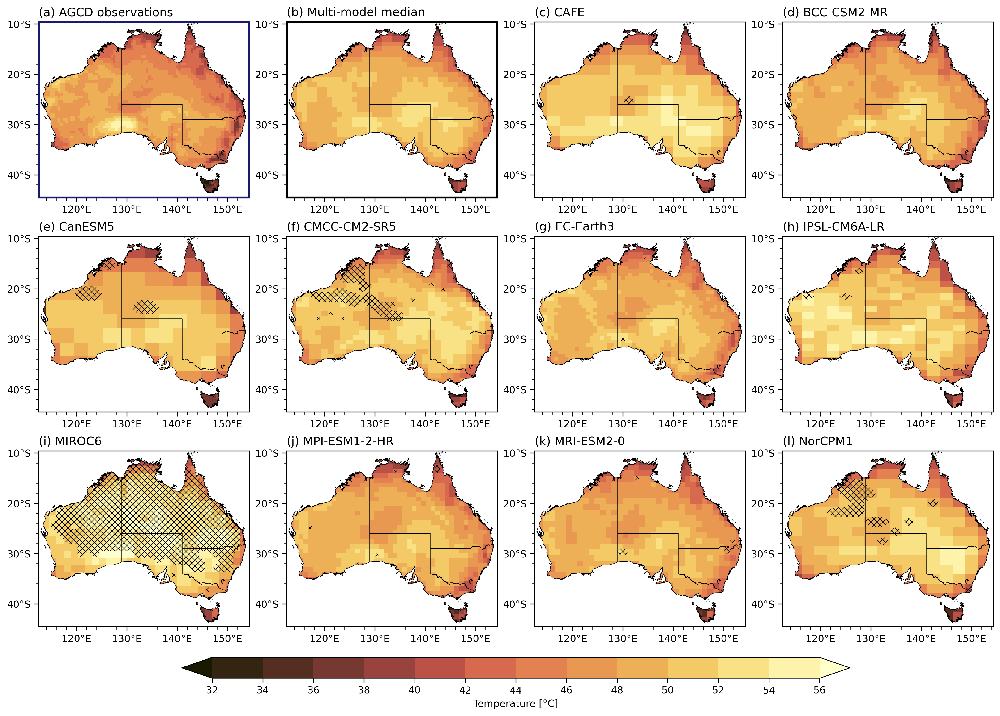

In [11]:
plot_time_agg(info, var, "maximum", plot_dict)

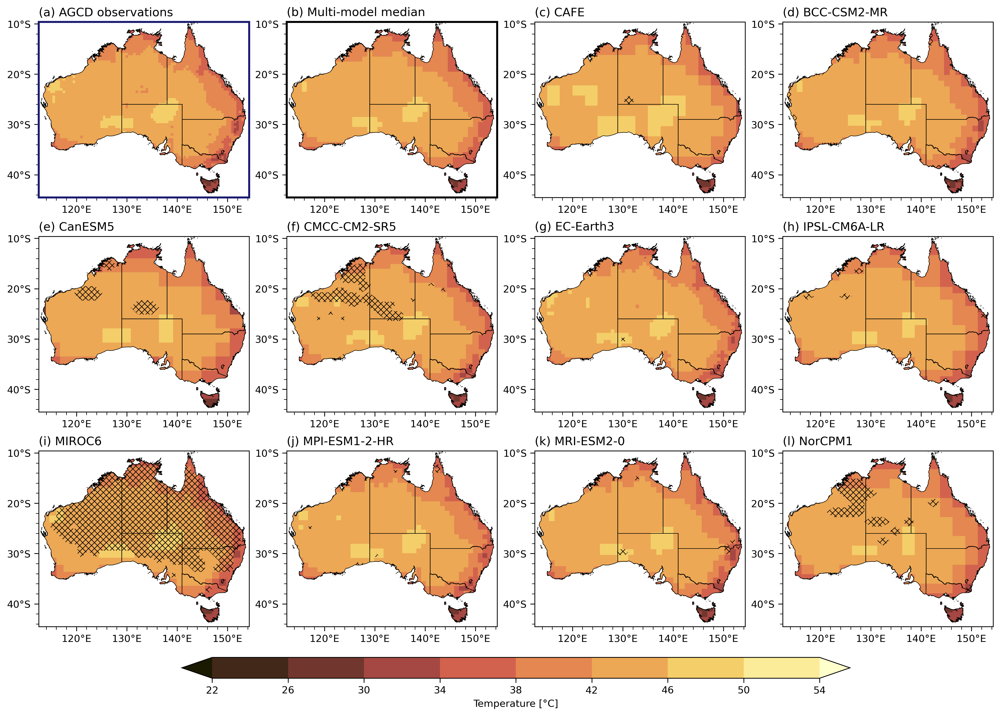

In [12]:
plot_time_agg(info, var, "median", plot_dict_avg)

### Metric maximum (subsampled)

Number of obs samples: 63


KeyboardInterrupt: 

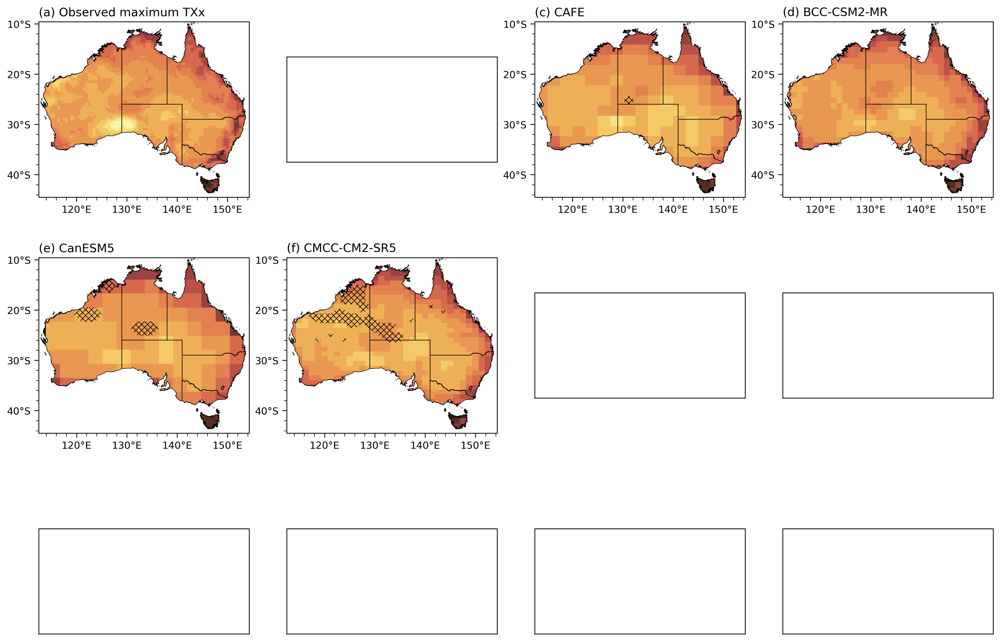

In [13]:
plot_time_agg_subsampled(info, obs, "maximum", plot_dict, 10000)

### Model minus observation anomalies

/g/data/xv83/as3189/conda/envs/unseen/lib/python3.11/site-packages/xesmf/frontend.py:95: UserWarning: Variables {'lon_bnds'} not found in object but are referred to in the CF attributes.
  lon_bnds = ds.cf.get_bounds('longitude')
/g/data/xv83/as3189/conda/envs/unseen/lib/python3.11/site-packages/xesmf/frontend.py:95: UserWarning: Variables {'lon_bnds'} not found in object but are referred to in the CF attributes.
  lon_bnds = ds.cf.get_bounds('longitude')
/g/data/xv83/as3189/conda/envs/unseen/lib/python3.11/site-packages/xesmf/frontend.py:95: UserWarning: Variables {'lon_bnds'} not found in object but are referred to in the CF attributes.
  lon_bnds = ds.cf.get_bounds('longitude')
/g/data/xv83/as3189/conda/envs/unseen/lib/python3.11/site-packages/xesmf/frontend.py:95: UserWarning: Variables {'lon_bnds'} not found in object but are referred to in the CF attributes.
  lon_bnds = ds.cf.get_bounds('longitude')
/g/data/xv83/as3189/conda/envs/unseen/lib/python3.11/site-packages/xesmf/fronten

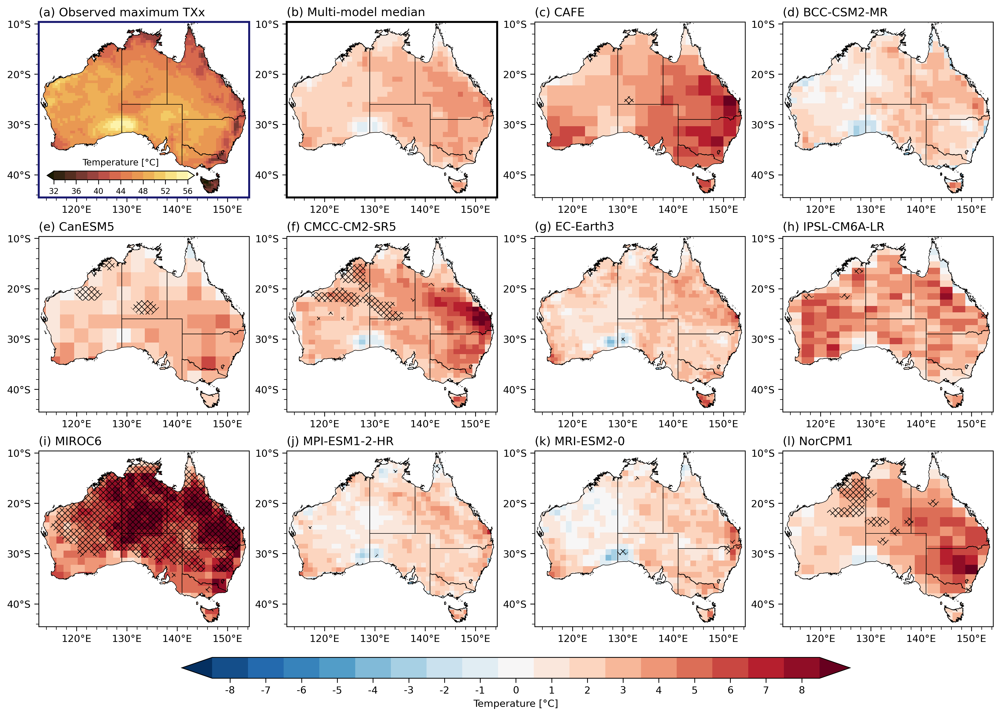

/g/data/xv83/as3189/conda/envs/unseen/lib/python3.11/site-packages/xesmf/frontend.py:95: UserWarning: Variables {'lon_bnds'} not found in object but are referred to in the CF attributes.
  lon_bnds = ds.cf.get_bounds('longitude')
/g/data/xv83/as3189/conda/envs/unseen/lib/python3.11/site-packages/xesmf/frontend.py:95: UserWarning: Variables {'lon_bnds'} not found in object but are referred to in the CF attributes.
  lon_bnds = ds.cf.get_bounds('longitude')
/g/data/xv83/as3189/conda/envs/unseen/lib/python3.11/site-packages/xesmf/frontend.py:95: UserWarning: Variables {'lon_bnds'} not found in object but are referred to in the CF attributes.
  lon_bnds = ds.cf.get_bounds('longitude')
/g/data/xv83/as3189/conda/envs/unseen/lib/python3.11/site-packages/xesmf/frontend.py:95: UserWarning: Variables {'lon_bnds'} not found in object but are referred to in the CF attributes.
  lon_bnds = ds.cf.get_bounds('longitude')
/g/data/xv83/as3189/conda/envs/unseen/lib/python3.11/site-packages/xesmf/fronten

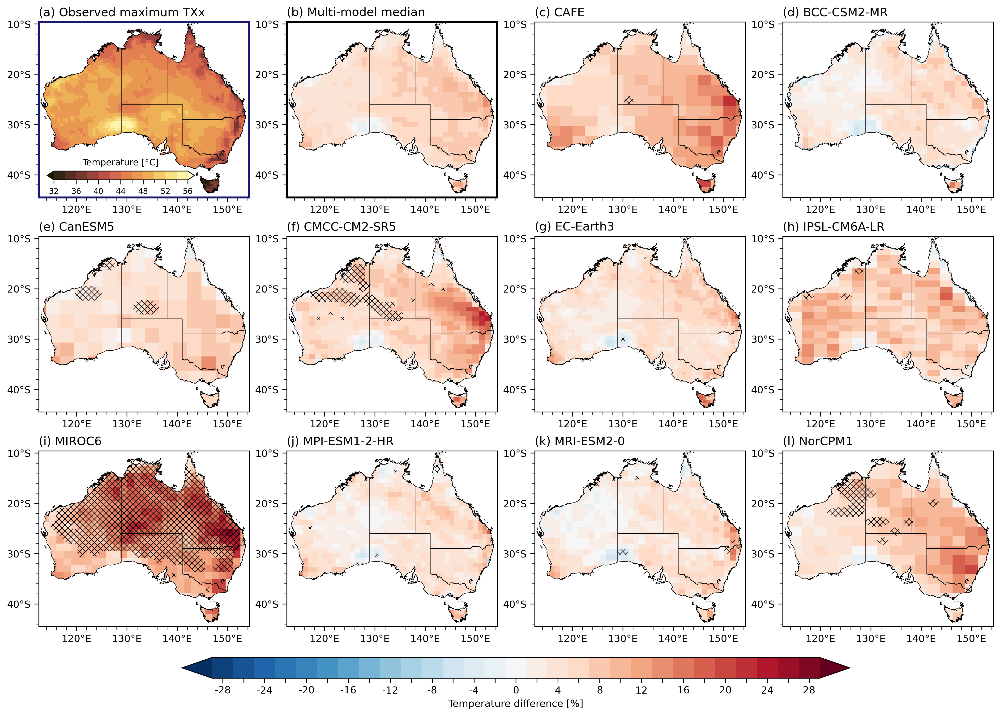

/g/data/xv83/as3189/conda/envs/unseen/lib/python3.11/site-packages/xesmf/frontend.py:95: UserWarning: Variables {'lon_bnds'} not found in object but are referred to in the CF attributes.
  lon_bnds = ds.cf.get_bounds('longitude')
/g/data/xv83/as3189/conda/envs/unseen/lib/python3.11/site-packages/xesmf/frontend.py:95: UserWarning: Variables {'lon_bnds'} not found in object but are referred to in the CF attributes.
  lon_bnds = ds.cf.get_bounds('longitude')
/g/data/xv83/as3189/conda/envs/unseen/lib/python3.11/site-packages/xesmf/frontend.py:95: UserWarning: Variables {'lon_bnds'} not found in object but are referred to in the CF attributes.
  lon_bnds = ds.cf.get_bounds('longitude')
/g/data/xv83/as3189/conda/envs/unseen/lib/python3.11/site-packages/xesmf/frontend.py:95: UserWarning: Variables {'lon_bnds'} not found in object but are referred to in the CF attributes.
  lon_bnds = ds.cf.get_bounds('longitude')
/g/data/xv83/as3189/conda/envs/unseen/lib/python3.11/site-packages/xesmf/fronten

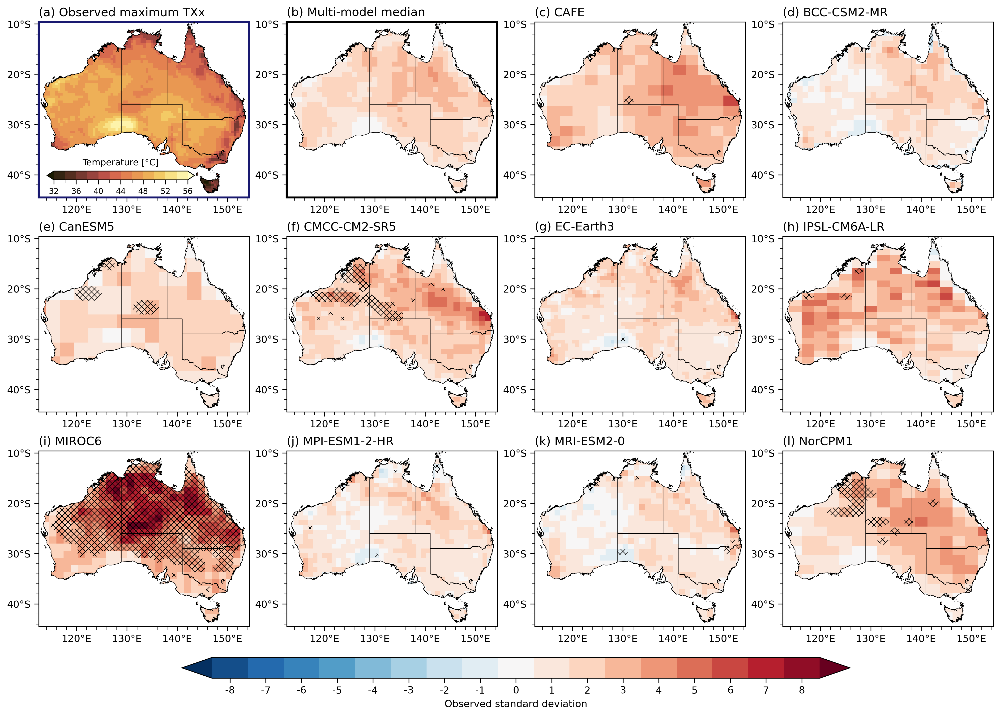

/g/data/xv83/as3189/conda/envs/unseen/lib/python3.11/site-packages/xesmf/frontend.py:95: UserWarning: Variables {'lon_bnds'} not found in object but are referred to in the CF attributes.
  lon_bnds = ds.cf.get_bounds('longitude')
/g/data/xv83/as3189/conda/envs/unseen/lib/python3.11/site-packages/xesmf/frontend.py:95: UserWarning: Variables {'lon_bnds'} not found in object but are referred to in the CF attributes.
  lon_bnds = ds.cf.get_bounds('longitude')
/g/data/xv83/as3189/conda/envs/unseen/lib/python3.11/site-packages/xesmf/frontend.py:95: UserWarning: Variables {'lon_bnds'} not found in object but are referred to in the CF attributes.
  lon_bnds = ds.cf.get_bounds('longitude')
/g/data/xv83/as3189/conda/envs/unseen/lib/python3.11/site-packages/xesmf/frontend.py:95: UserWarning: Variables {'lon_bnds'} not found in object but are referred to in the CF attributes.
  lon_bnds = ds.cf.get_bounds('longitude')
/g/data/xv83/as3189/conda/envs/unseen/lib/python3.11/site-packages/xesmf/fronten

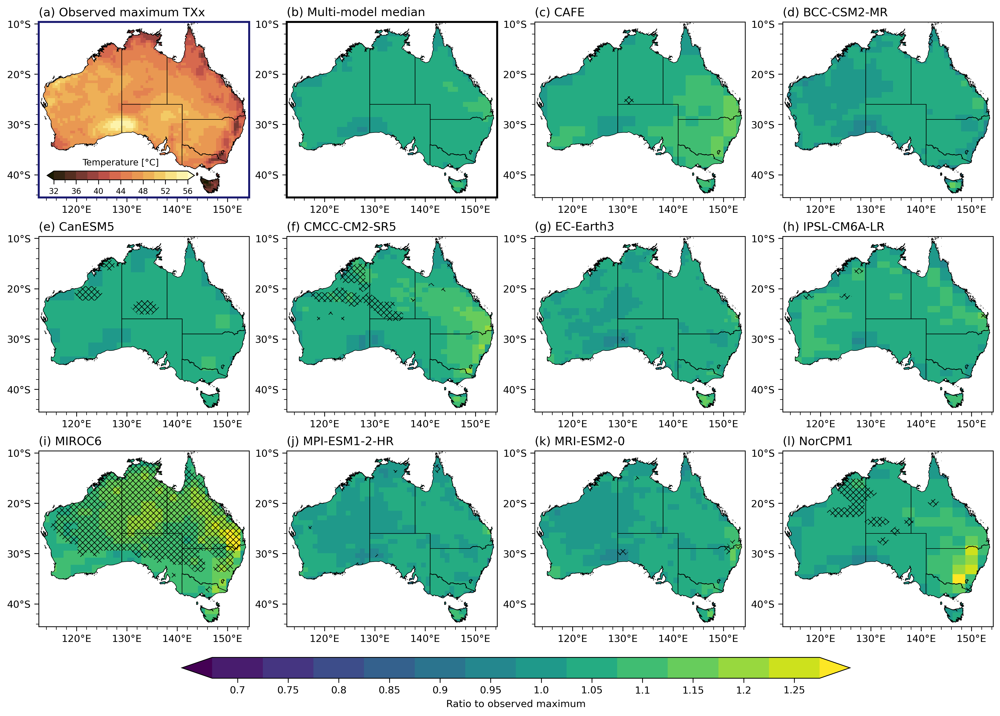

In [14]:
for anom in ["anom", "anom_pct", "anom_std", "anom_2000yr"]:
    plot_obs_anom(info, obs, var, "maximum", anom, covariate_base, plot_dict)

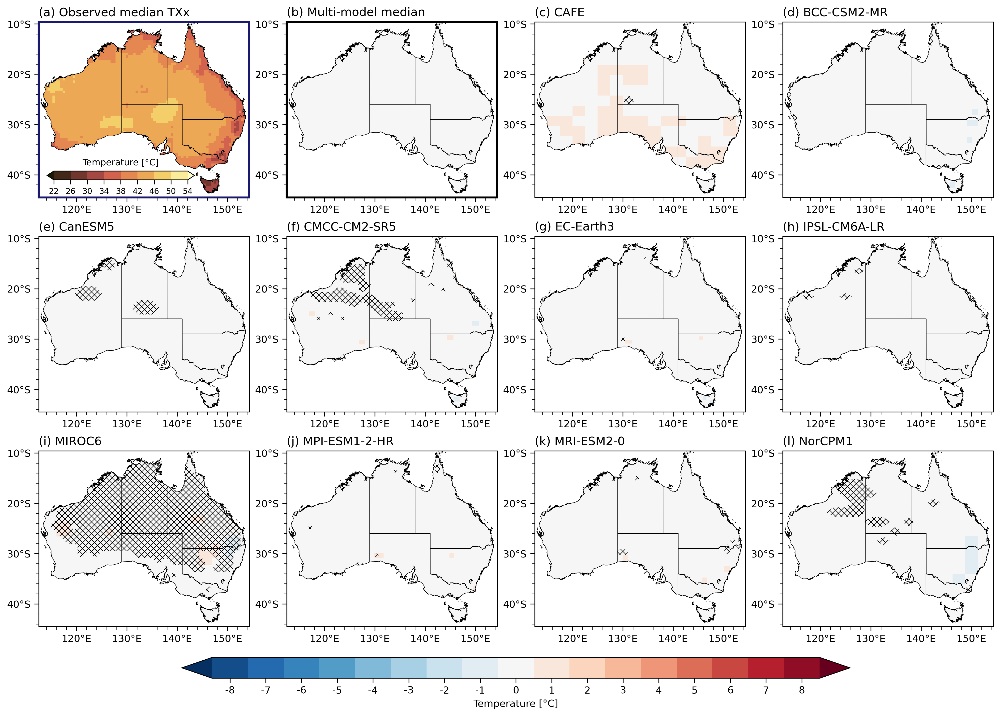

In [ ]:
plot_obs_anom(
    info,
    obs,
    var,
    "median",
    "anom",
    covariate_base,
    plot_dict_avg,
)

### Seasonality/event year

In [20]:
# from matplotlib.colors import LinearSegmentedColormap

# cmap = month_cmap  # _alt if metric == "txx" else month_cmap
# cmap = plt.cm.managua

# # colors = cmap(np.linspace(0, 1, 12))
# # cmap = LinearSegmentedColormap.from_list(colors, colors, N=n_bin)
# n = np.linspace(0, 0.9, 100)
# cmap = plt.cm.twilight(np.linspace(0, 0.8, 100))
# cmap = LinearSegmentedColormap.from_list("tw", colors=cmap)


def plot_event_month_mode(
    info, plot_dict, min_count=4, cmap=month_cmap, add_labels=True
):
    """Plot map of the most common month when event occurs."""

    cbar_kwargs = dict(
        cmap=cmap,
        ticks=np.arange(0.5, 13.5),
        ticklabels=list(calendar.month_name)[1:],
        extend="neither",
    )

    # Add white space for ACT, TAS, VIC labels
    map_kwargs = dict(xlim=(112.5, 157)) if add_labels else {}

    fig, ax = plt.subplots(3, 4, subplot_kw=dict(projection=PlateCarree()))
    ax = ax.flatten()

    da_list = []  # Store data arrays for the multi-model mode
    for i, m in enumerate(info.keys()):

        da = xr.DataArray(
            mode(info[m].ds.event_time.dt.month, axis=0).mode,
            coords=dict(lat=info[m].ds.lat, lon=info[m].ds.lon),
            dims=["lat", "lon"],
        )
        if m in plot_dict["models"]:
            i += 1  # Leave ax[1] for the multi-model mode
            da_list.append(da)

        fig, ax[i], cs = map_subplot(
            fig,
            ax[i],
            da,
            title=f"{letters[i]} {info[m].title_name}",
            **cbar_kwargs,
            **map_kwargs,
        )

    # Multi-model mode
    dr_list = []
    for i, m in enumerate(plot_dict["models"]):
        regridder = shared_grid_regridder(info[m].ds, method="nearest_s2d")
        dr_list.append(regridder(da_list[i]))

    dm = xr.concat(dr_list, dim="model")
    mm_mode = mode(dm, axis=0, nan_policy="omit")
    dm = xr.DataArray(
        mm_mode.mode, coords=dict(lat=dm.lat, lon=dm.lon), dims=("lat", "lon")
    )
    counts = xr.DataArray(mm_mode.count, coords=dm.coords, dims=dm.dims)

    i = 1
    fig, ax[i], cs = map_subplot(
        fig,
        ax[i],
        dm,
        title=f"{letters[i]} Multi-model mode",
        hatching=counts < min_count,
        **cbar_kwargs,
        **map_kwargs,
    )
    if add_labels:
        # Add Australian state and territory labels to the first map
        add_aus_state_labels(ax[0], color="black", fontsize=12, fontweight="bold")

    add_shared_colorbar(
        fig,
        ax,
        cs,
        label=f"Most common month of {plot_dict['metric']} occurrence",
        **cbar_kwargs,
    )

    ax = extra_subplot_formatting(ax)

    outfile = f"{plot_dict['fig_dir']}/month_mode_{plot_dict['filestem']}.png"
    plt.savefig(outfile, bbox_inches="tight")
    plt.show()
    plt.close()

In [ ]:
# autoreload
%load_ext autoreload
cmap = month_cmap
# from spatial_plots_multimodel import plot_event_month_mode
# colors = cmap(np.linspace(0, 1, 12))
# # shift colors so that summer is in middle of colormap
# colors = np.roll(colors, 3, axis=0)
# cmap = LinearSegmentedColormap.from_list("tmp", colors)
plot_event_month_mode(
    info, plot_dict, cmap=cmap, add_labels=True if metric == "txx" else False
)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


/g/data/xv83/unseen-projects/code/spatial_plots_multimodel.py:399: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  for name, centroid in zip(regions.ABBREV, regions.centroid):


/g/data/xv83/unseen-projects/code/spatial_plots_multimodel.py:399: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  for name, centroid in zip(regions.ABBREV, regions.centroid):


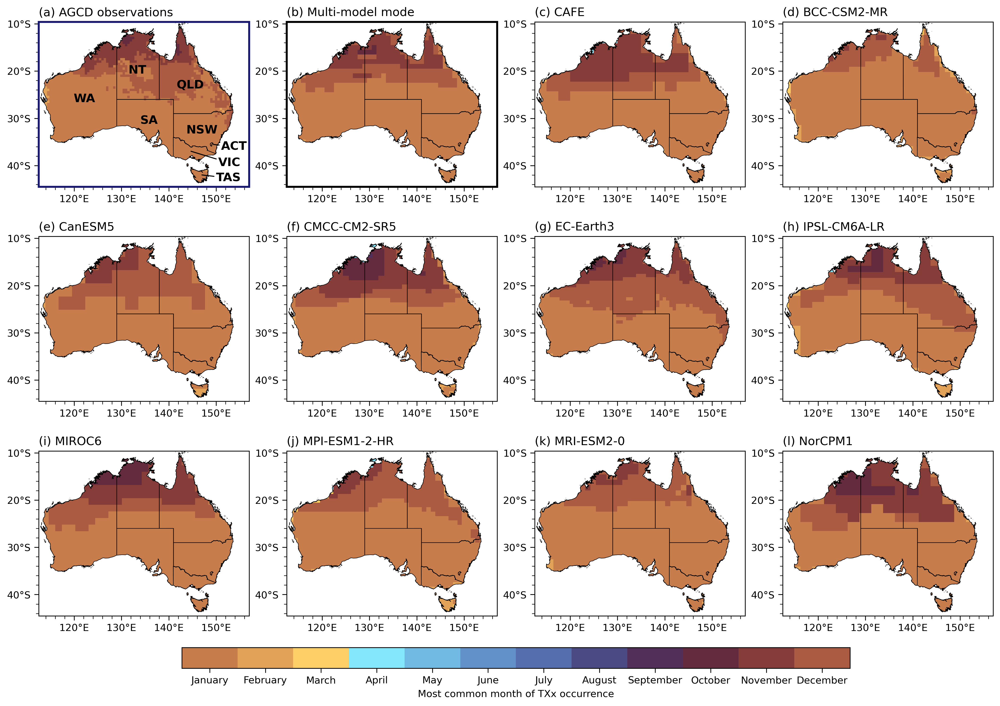

In [61]:
cmap = plt.cm.managua_r
colors = cmap(np.linspace(0, 1, 12))
# shift colors so that summer is in middle of colormap
colors = np.roll(colors, 3, axis=0)

cmap = LinearSegmentedColormap.from_list("tmp", colors)
plot_event_month_mode(
    info, plot_dict, cmap=cmap, add_labels=True if metric == "txx" else False
)

In [74]:
def plot_event_month_mode(
    info, plot_dict, min_count=4, cmap=month_cmap, add_labels=True
):
    """Plot map of the most common month when event occurs."""

    cbar_kwargs = dict(
        cmap=cmap,
        ticks=np.arange(0.5, 13.5),
        ticklabels=list(calendar.month_name)[1:],
        extend="neither",
    )

    # Add white space for ACT, TAS, VIC labels
    map_kwargs = dict(xlim=(112.5, 157)) if add_labels else {}

    fig, ax = plt.subplots(3, 4, subplot_kw=dict(projection=PlateCarree()))
    ax = ax.flatten()

    da_list = []  # Store data arrays for the multi-model mode
    for i, m in enumerate(info.keys()):

        da = xr.DataArray(
            mode(info[m].ds.event_time.dt.month, axis=0).mode,
            coords=dict(lat=info[m].ds.lat, lon=info[m].ds.lon),
            dims=["lat", "lon"],
        )
        if m in plot_dict["models"]:
            i += 1  # Leave ax[1] for the multi-model mode
            da_list.append(da)

        fig, ax[i], cs = map_subplot(
            fig,
            ax[i],
            da,
            title=f"{letters[i]} {info[m].title_name}",
            **cbar_kwargs,
            **map_kwargs,
        )

        hatching = xr.where(
            (da < 3) & (da > 9), da * 0 + 1, 0
        )  # Hatching for winter/cold months
        ax[i].contourf(
            hatching.lon,
            hatching.lat,
            hatching,
            alpha=0,
            hatches=["", "////"],
            transform=PlateCarree(),
        )
    # Multi-model mode
    dr_list = []
    for i, m in enumerate(plot_dict["models"]):
        regridder = shared_grid_regridder(info[m].ds, method="nearest_s2d")
        dr_list.append(regridder(da_list[i]))

    dm = xr.concat(dr_list, dim="model")
    mm_mode = mode(dm, axis=0, nan_policy="omit")
    dm = xr.DataArray(
        mm_mode.mode, coords=dict(lat=dm.lat, lon=dm.lon), dims=("lat", "lon")
    )
    counts = xr.DataArray(mm_mode.count, coords=dm.coords, dims=dm.dims)

    i = 1
    fig, ax[i], cs = map_subplot(
        fig,
        ax[i],
        dm,
        title=f"{letters[i]} Multi-model mode",
        # hatching=counts < min_count,
        **cbar_kwargs,
        **map_kwargs,
    )
    if add_labels:
        # Add Australian state and territory labels to the first map
        add_aus_state_labels(ax[0], color="black", fontsize=12, fontweight="bold")

    add_shared_colorbar(
        fig,
        ax,
        cs,
        label=f"Most common month of {plot_dict['metric']} occurrence",
        **cbar_kwargs,
    )

    ax = extra_subplot_formatting(ax)

    outfile = f"{plot_dict['fig_dir']}/month_mode_{plot_dict['filestem']}.png"
    plt.savefig(outfile, bbox_inches="tight")
    plt.show()
    plt.close()

/g/data/xv83/unseen-projects/code/spatial_plots_multimodel.py:399: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  for name, centroid in zip(regions.ABBREV, regions.centroid):


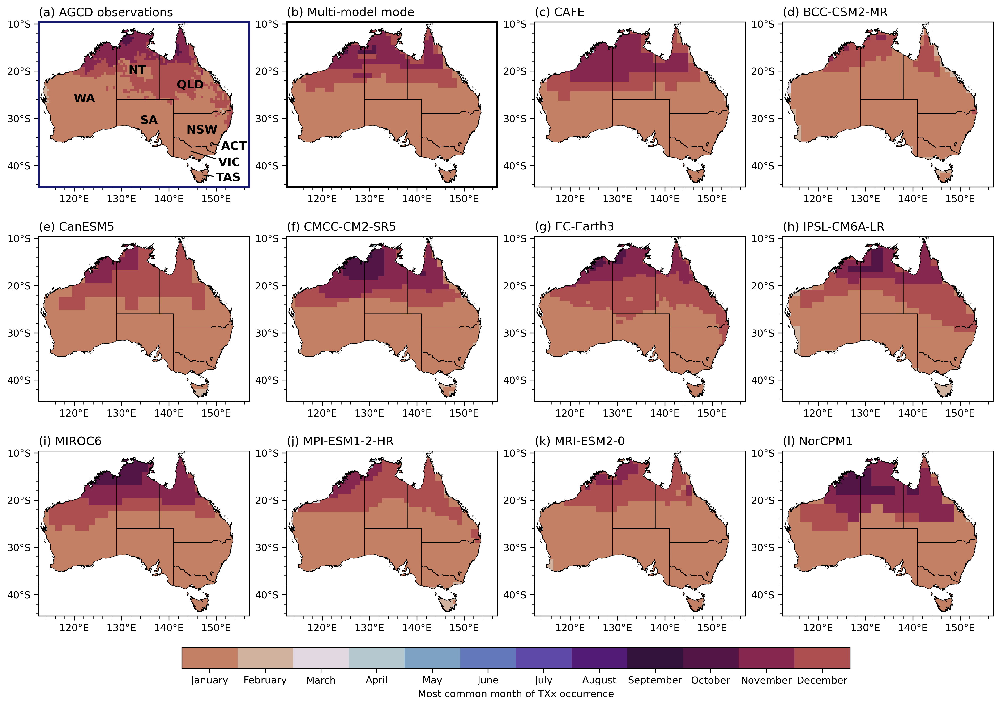

In [75]:
n = np.linspace(0, 0.9, 100)
cmap = plt.cm.twilight  # (np.linspace(0, 0.8, 100))
colors = cmap(np.linspace(0, 0.9, 12))
# shift colors so that summer is in middle of colormap
colors = np.roll(colors, 2, axis=0)
cmap = LinearSegmentedColormap.from_list("tw", colors=colors)
# hatching winter/cold months

plot_event_month_mode(
    info,
    plot_dict,
    cmap=cmap,
    add_labels=True if metric == "txx" else False,
)

/g/data/xv83/unseen-projects/code/spatial_plots_multimodel.py:399: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  for name, centroid in zip(regions.ABBREV, regions.centroid):


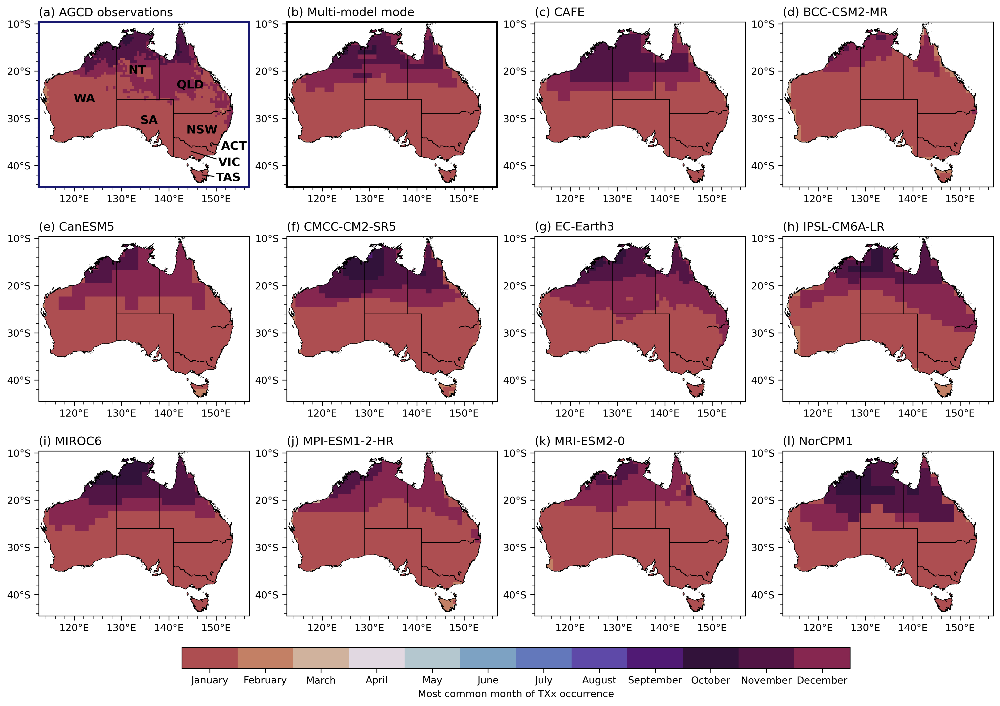

In [53]:
n = np.linspace(0, 0.9, 100)
cmap = plt.cm.twilight  # (np.linspace(0, 0.8, 100))
colors = cmap(np.linspace(0, 0.9, 12))
# shift colors so that summer is in middle of colormap
colors = np.roll(colors, 3, axis=0)
cmap = LinearSegmentedColormap.from_list("tw", colors=colors)
plot_event_month_mode(
    info, plot_dict, cmap=cmap, add_labels=True if metric == "txx" else False
)

/g/data/xv83/unseen-projects/code/spatial_plots_multimodel.py:399: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  for name, centroid in zip(regions.ABBREV, regions.centroid):


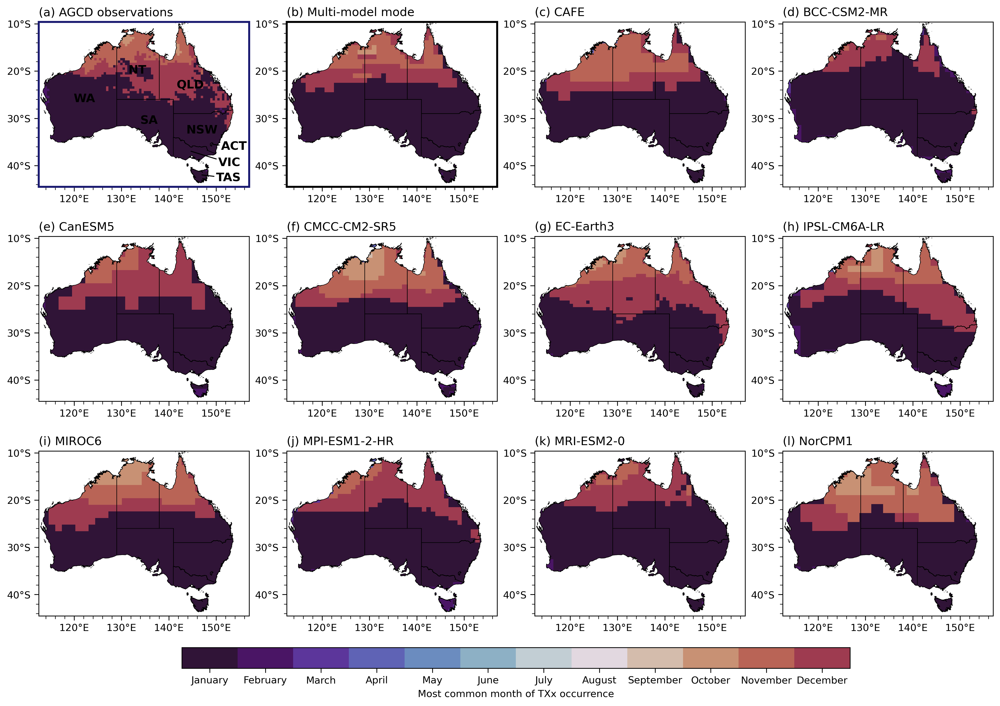

In [ ]:
n = np.linspace(0, 0.9, 100)
cmap = plt.cm.twilight_shifted(np.linspace(0, 0.8, 100))
cmap = LinearSegmentedColormap.from_list("tw", colors=cmap)
plot_event_month_mode(
    info, plot_dict, cmap=cmap, add_labels=True if metric == "txx" else False
)

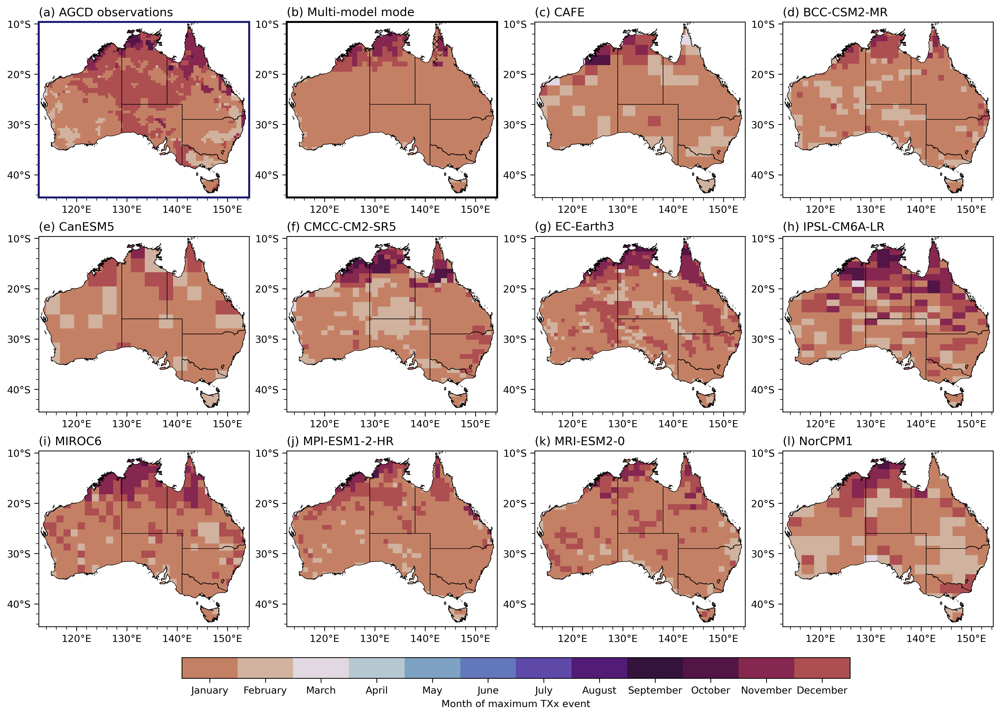

In [ ]:
# n = np.linspace(0, 0.9, 100)
# cmap = plt.cm.twilight  # (np.linspace(0, 0.8, 100))
# colors = cmap(np.linspace(0, 0.9, 12))
# # shift colors so that summer is in middle of colormap
# colors = np.roll(colors, 2, axis=0)
# cmap = LinearSegmentedColormap.from_list("tw", colors=colors)
# # hatching winter/cold months

plot_record_event_month(info, plot_dict, time_agg=time_agg, cmap=cmap)

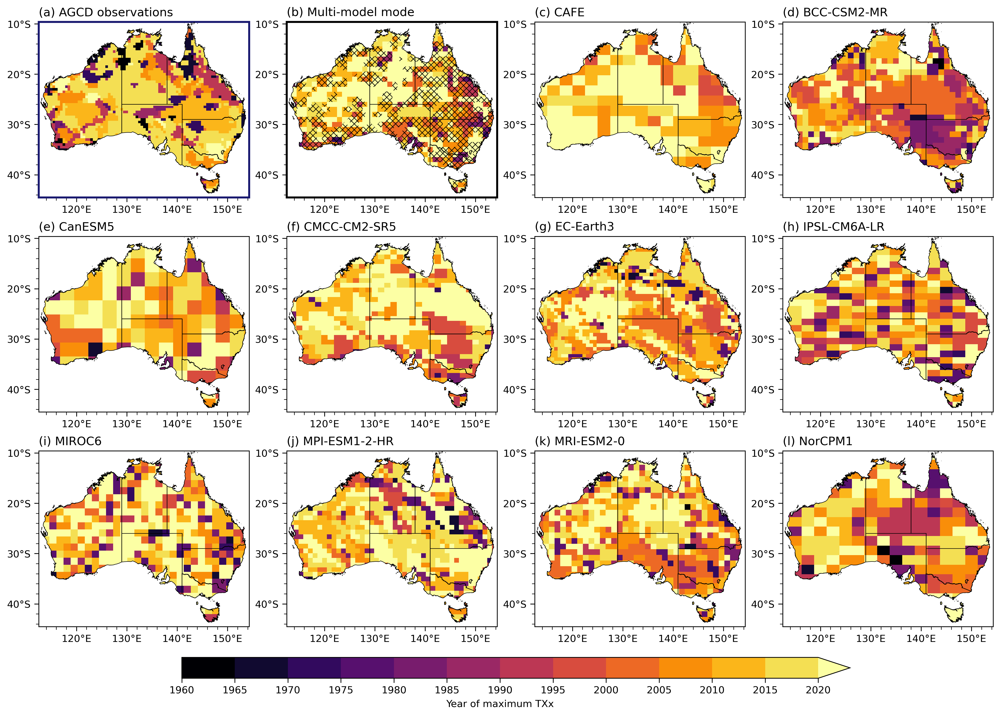

In [ ]:
plot_event_year(info, var, time_agg, plot_dict, ticks=np.arange(1960, 2025, 5))

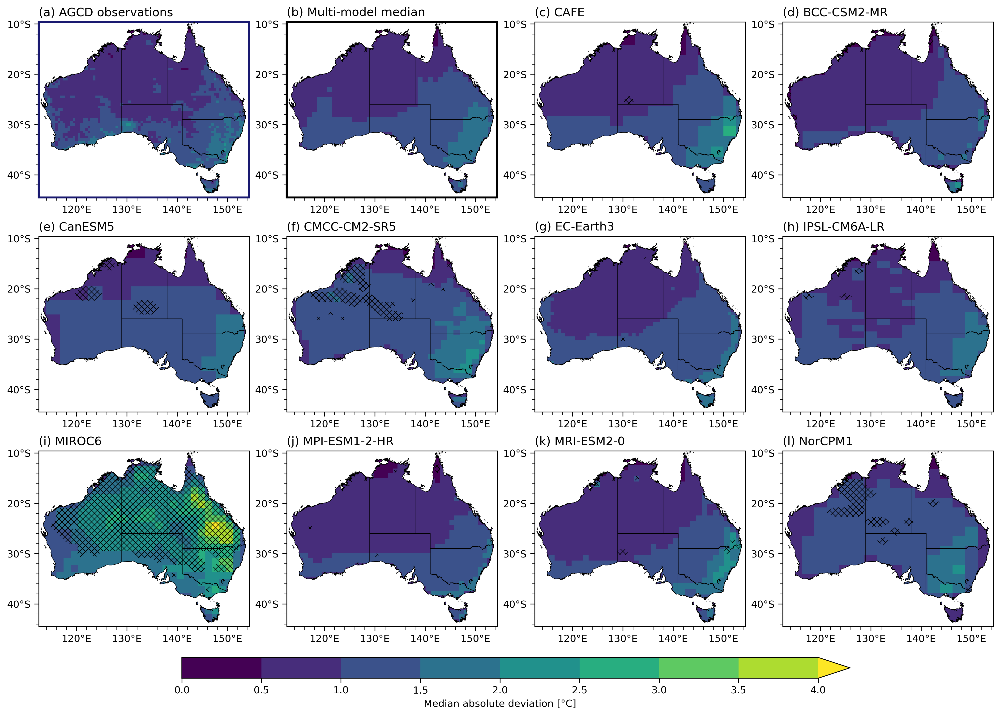

In [21]:
plot_metric_variability(info, var, plot_dict, ticks=std_dev_ticks)

### GEV parameters

In [ ]:
# GEV/empirical
for param in ["c", "location_0", "location_1", "scale_0", "scale_1"]:
    plot_nonstationary_gev_param(info, param, plot_dict)

### Annual exceedance probability (AEP)

In [ ]:
aep = 1

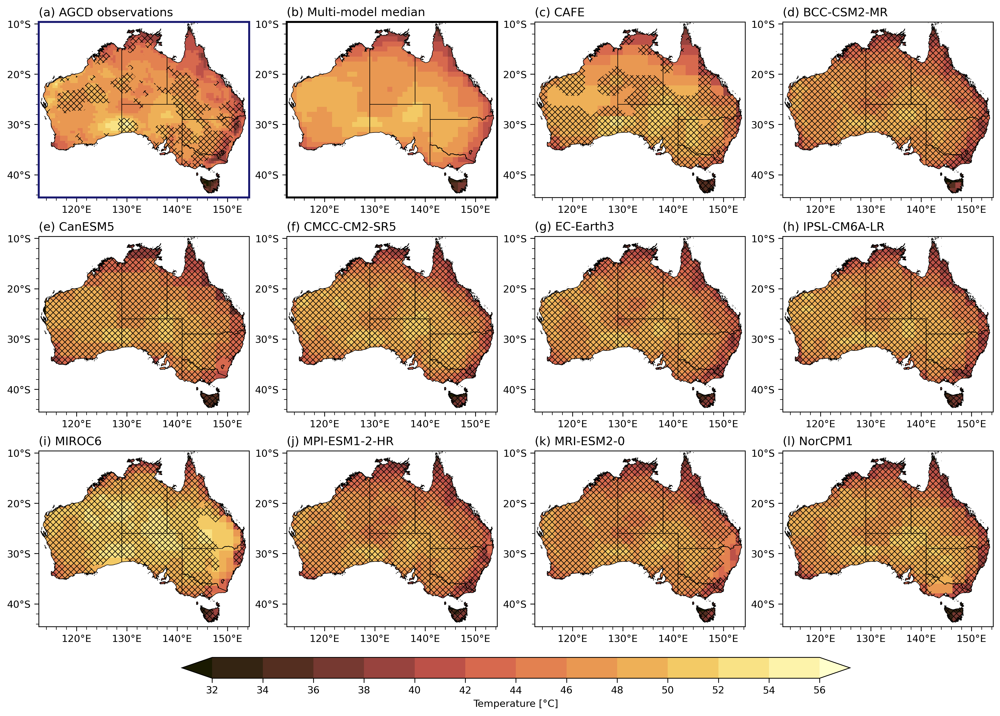

In [ ]:
plot_aep_empirical(info, plot_dict, var, aep=aep)

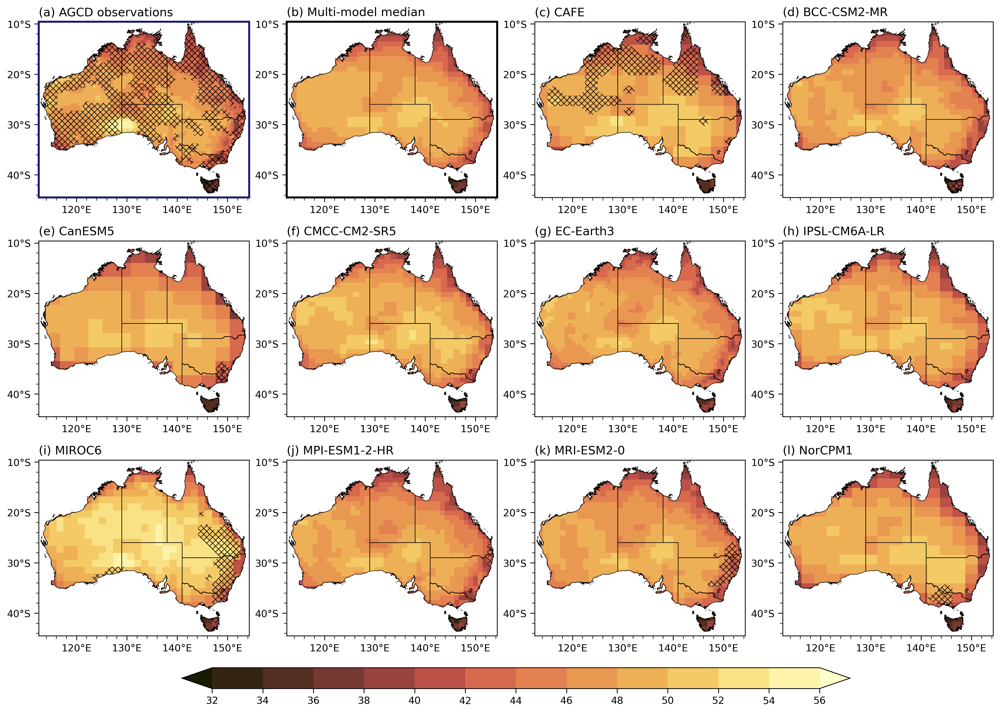

In [ ]:
plot_aep(info, plot_dict, covariates[-1], aep=aep)

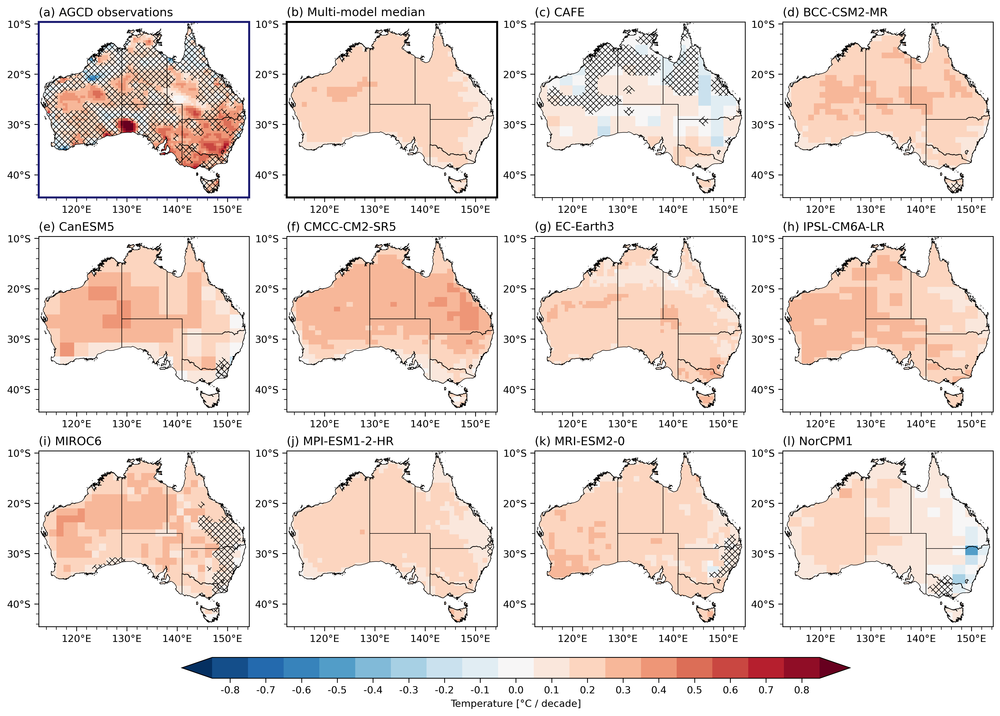

In [ ]:
plot_aep_trend(
    info,
    plot_dict,
    covariates,
    aep=aep,
)

# Cumulative annual exceedance probability

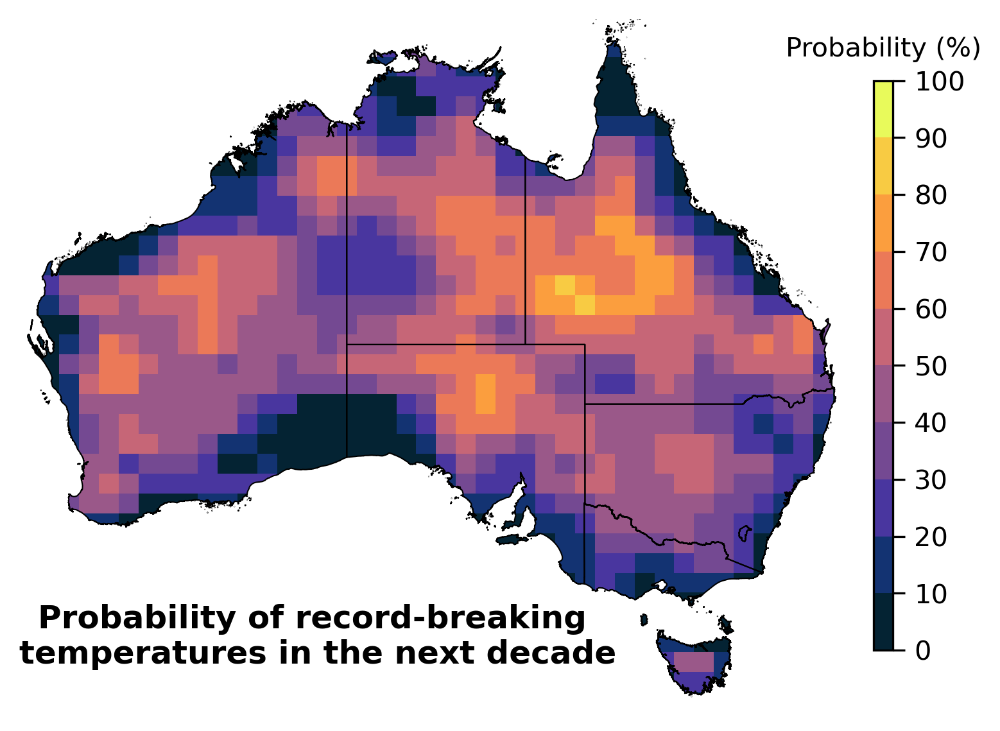

In [ ]:
plot_abstract(
    info, plot_dict, time_agg=time_agg, start_year=2025, n_years=10
)  # For graphic abstract (multi-model median only)

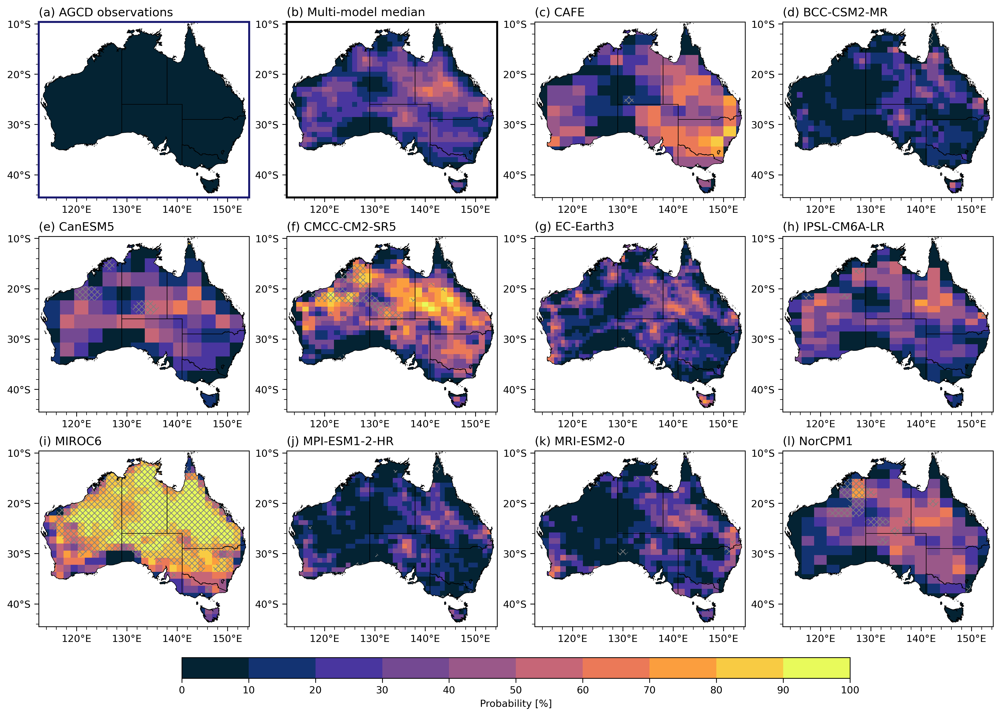

In [ ]:
plot_new_record_probability_empirical(
    info, plot_dict, var, time_agg=time_agg, n_years=10
)

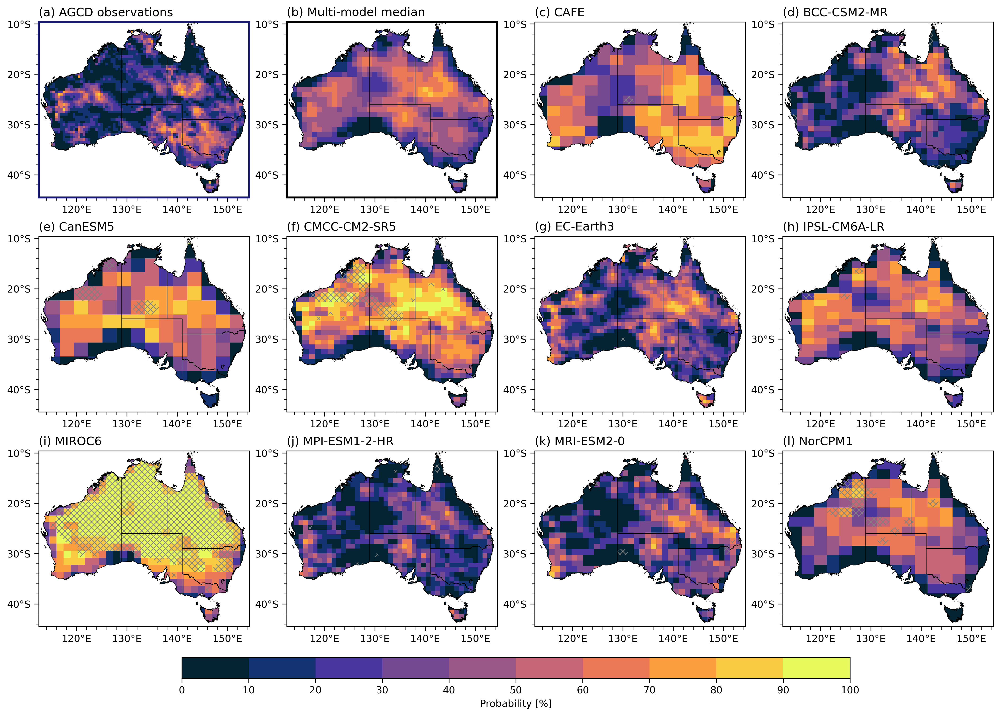

In [ ]:
plot_new_record_probability(
    info, plot_dict, covariate_base, time_agg=time_agg, n_years=10
)

In [13]:
n_years = 10
da_list = []  # Store data arrays for the multi-model median
for i, m in enumerate(info.keys()):
    _, cumulative_probability = new_record_probability_empirical(
        info[m].ds[var],
        info[m].obs_ds[var],
        n_years,
        time_agg,
        time_dim=info[m].time_dim,
        init_dim="init_date" if m != info[m].obs_name else "time",
    )
    da = cumulative_probability * 100

    if m in plot_dict["models"]:
        i += 1  # Leave ax[1] for the multi-model median
        da_list.append(da)  # Only append model data


# Multi-model median
i = 1
dm = multimodel_avg(info, plot_dict["models"], da_list)
dr = multimodel_avg(info, plot_dict["models"], da_list, func=None)
# Median absolute deviation
mad = np.fabs((dr - dm)).median("model")
dr_iqr = dr.quantile([0.25, 0.75], dim="model")
iqr_diff = dr_iqr.isel(quantile=1) - dr_iqr.isel(quantile=0)

Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x7fdb6ad65950>>
Traceback (most recent call last):
  File "/g/data/xv83/as3189/conda/envs/unseen/lib/python3.11/site-packages/ipykernel/ipkernel.py", line 775, in _clean_thread_parent_frames
    def _clean_thread_parent_frames(

KeyboardInterrupt: 


KeyboardInterrupt: 

In [16]:
from unseen import eva, general_utils

start_year = 2025
# Get the event record (return period) for the obs data
da_list = []  # Store data arrays for the multi-model median
# ci_list = []
for i, m in enumerate(info.keys()):
    # Get the event record (return period) for the obs data
    # N.B. The obs data in info[m] is already subset to the model time period
    record = info[m].obs_ds[info[m].var].reduce(func_dict[time_agg], dim="time")
    if info[m].is_model():
        record = general_utils.regrid(record, info[m].ds)
    cumulative_probability = nonstationary_new_record_probability(
        record, info[m].ds.dparams_ns, start_year, n_years, info[m].time_dim
    )

    da = cumulative_probability * 100
    if m in plot_dict["models"]:
        da_list.append(da)  # Only append model data
    # ci = eva.gev_confidence_interval(info[m].ds, info[m].ds.dparams_ns, return_level=record, covariate=start_year + int(n_years/2), bootstrap_method="parametric")
    # ci_list.append(ci)

# Multi-model median absolute deviation
dr = multimodel_avg(info, plot_dict["models"], da_list, func=None)
mad = np.fabs((dr - dr.median("model"))).median("model")

NameError: name 'n_years' is not defined

/g/data/xv83/as3189/conda/envs/unseen/lib/python3.11/site-packages/xesmf/frontend.py:95: UserWarning: Variables {'lon_bnds'} not found in object but are referred to in the CF attributes.
  lon_bnds = ds.cf.get_bounds('longitude')
/g/data/xv83/as3189/conda/envs/unseen/lib/python3.11/site-packages/xesmf/frontend.py:95: UserWarning: Variables {'lon_bnds'} not found in object but are referred to in the CF attributes.
  lon_bnds = ds.cf.get_bounds('longitude')
/g/data/xv83/as3189/conda/envs/unseen/lib/python3.11/site-packages/xesmf/frontend.py:95: UserWarning: Variables {'lon_bnds'} not found in object but are referred to in the CF attributes.
  lon_bnds = ds.cf.get_bounds('longitude')
/g/data/xv83/as3189/conda/envs/unseen/lib/python3.11/site-packages/xesmf/frontend.py:95: UserWarning: Variables {'lon_bnds'} not found in object but are referred to in the CF attributes.
  lon_bnds = ds.cf.get_bounds('longitude')
/g/data/xv83/as3189/conda/envs/unseen/lib/python3.11/site-packages/xesmf/fronten

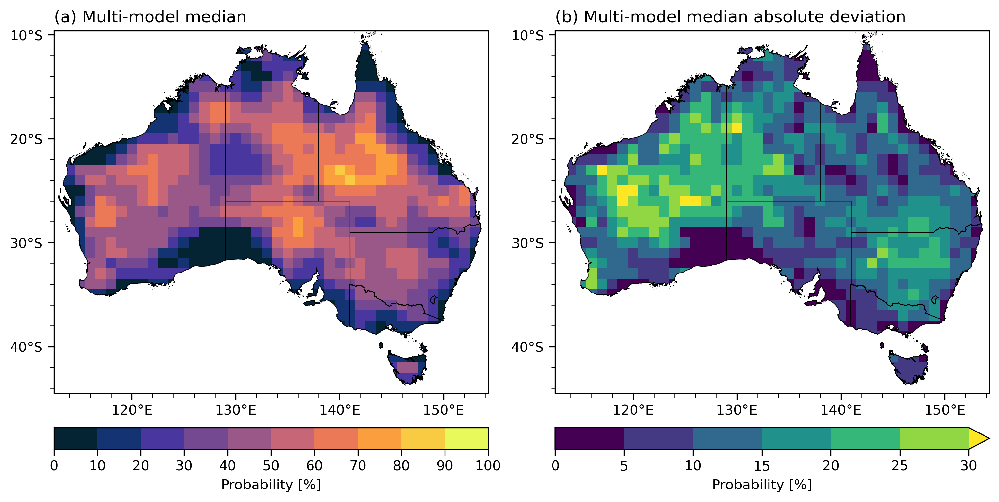

In [ ]:
# def plot_new_record_probability_model_spread(
#     info, plot_dict, start_year, time_agg, n_years=10, mad_ticks=np.arange(0, 35, 5)
# ):
#     """Plot map of the MMM probability of breaking the obs record and model spread."""

#     cbar_kwargs = dict(
#         cmap=cmocean.cm.thermal,
#         ticks=np.arange(0, 101, 10),
#         extend="neither",
#     )
#     # Get the event record (return period) for the obs data
#     da_list = []  # Store data arrays for the multi-model median

#     for i, m in enumerate(info.keys()):
#         # Get the event record (return period) for the obs data
#         # N.B. The obs data in info[m] is already subset to the model time period
#         record = info[m].obs_ds[info[m].var].reduce(func_dict[time_agg], dim="time")
#         if info[m].is_model():
#             record = general_utils.regrid(record, info[m].ds)
#         cumulative_probability = nonstationary_new_record_probability(
#             record, info[m].ds.dparams_ns, start_year, n_years, info[m].time_dim
#         )

#         da = cumulative_probability * 100
#         if m in plot_dict["models"]:
#             da_list.append(da)  # Only append model data

#     # Multi-model median absolute deviation
#     dr = multimodel_avg(info, plot_dict["models"], da_list, func=None)
#     mad = np.fabs((dr - dr.median("model"))).median("model")

#     fig, ax = plt.subplots(
#         1, 2, figsize=[10, 7], subplot_kw=dict(projection=PlateCarree())
#     )

#     i = 0
#     fig, ax[i], cs = map_subplot(
#         fig,
#         ax[i],
#         dr.median("model"),
#         title=f"{letters[i]} Multi-model median",
#         **cbar_kwargs,
#     )
#     add_shared_colorbar(
#         fig,
#         ax[i],
#         cs,
#         label="Probability [%]",
#         shrink=1,
#         pad=0.015,
#         aspect=20,
#         **cbar_kwargs,
#     )

#     i = 1
#     fig, ax[i], cs = map_subplot(
#         fig,
#         ax[i],
#         mad,
#         title=f"{letters[i]} Multi-model median absolute deviation",
#         cmap=plt.cm.viridis,
#         extend="max",
#         ticks=mad_ticks,
#     )
#     add_shared_colorbar(
#         fig,
#         ax[i],
#         cs,
#         shrink=1,
#         pad=0.015,
#         aspect=20,
#         label="Probability [%]",
#         ticks=mad_ticks,
#         cmap=plt.cm.viridis,
#         extend="max",
#     )

#     outfile = f"{plot_dict['fig_dir']}/new_record_probability_{n_years}-year_mad_{plot_dict['filestem']}.png"
#     plt.savefig(outfile, bbox_inches="tight")
#     plt.show()
#     plt.close()


plot_new_record_probability_model_spread(
    info, plot_dict, 2025, time_agg, n_years=10, mad_ticks=np.arange(0, 35, 5)
)

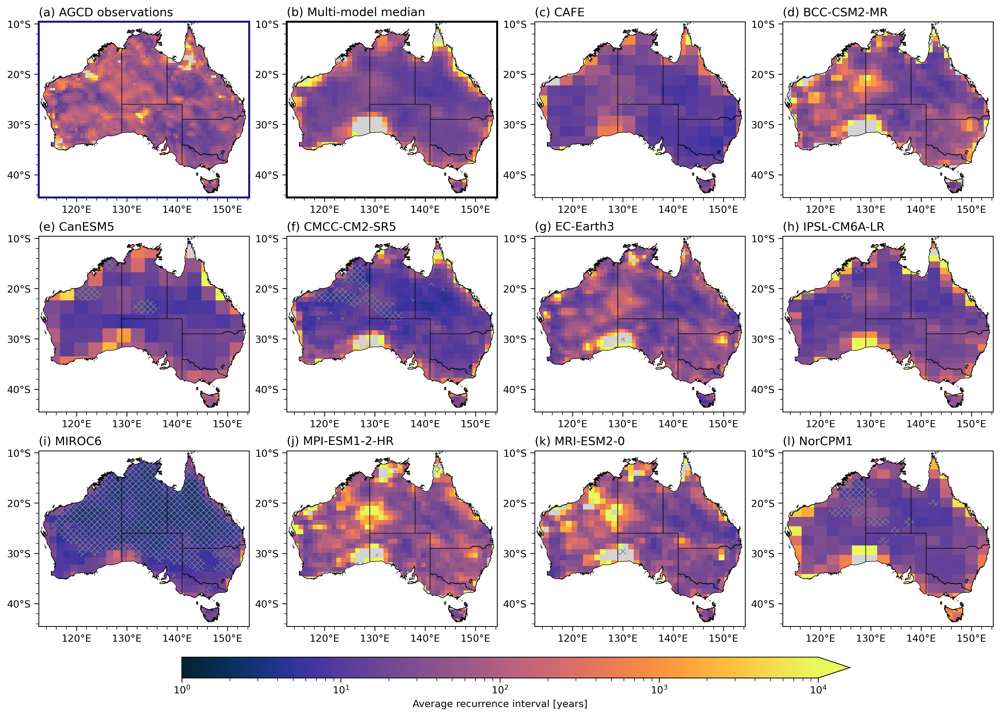

In [ ]:
plot_obs_ari(
    info,
    plot_dict,
    var,
    obs,
    covariate_base,
    time_agg=time_agg,
)